# Credit portfolio loss simulation

**Santiago Diaz Ricagno, Lead Data Scientist**

How much capital does a lender need against portfolio credit losses, and how much does the dependence assumption matter?

This notebook walks the published study: a synthetic 2,500-loan book, a one-factor Gaussian copula, a Student-t copula with a shared chi-square shock, and the Vasicek large-portfolio limit. Seeds and sample sizes come from `credit_sim.config`, so the figures match the README.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from credit_sim.analysis import run_analysis
from credit_sim.config import N_LOANS, N_SIMS, RHO, SEED, T_DF
from credit_sim.copula import gaussian_conditional_pd
from credit_sim.portfolio import (
    analytic_expected_loss,
    effective_loan_count,
    generate_portfolio,
    portfolio_summary,
)

pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print(f"Book size {N_LOANS:,} loans, {N_SIMS:,} scenarios, rho {RHO}, nu {T_DF:.0f}, seed {SEED}")

Book size 2,500 loans, 40,000 scenarios, rho 0.15, nu 5, seed 42


## The book

Loans are split across mortgage, consumer, SME, corporate, and CRE. A rating becomes a fixed one-year PD. LGD is a Beta draw around the sector mean, and exposure is lognormal. Both are drawn once, at origination.


In [2]:
portfolio = generate_portfolio(N_LOANS, SEED)
total_ead = portfolio.total_ead
analytic_el = analytic_expected_loss(portfolio)
print(f"Exposure ${total_ead / 1e6:,.1f} million")
el_share = 100 * analytic_el / total_ead
print(f"Analytic EL ${analytic_el / 1e6:,.2f} million ({el_share:.2f}% of exposure)")
print(f"Effective loans (1/HHI) {effective_loan_count(portfolio):,.0f}")
print(f"Largest loan {portfolio.ead.max() / total_ead:.2%} of exposure")

raw = portfolio_summary(portfolio)
view = pd.DataFrame(
    {
        "Loans": raw["Loans"].to_numpy(),
        "Exposure $m": raw["EAD"].to_numpy() / 1e6,
        "Exposure share %": 100 * raw["EAD share"].to_numpy(),
        "PD %": 100 * raw["PD"].to_numpy(),
        "LGD %": 100 * raw["LGD"].to_numpy(),
        "EL rate %": 100 * raw["EL rate"].to_numpy(),
        "EL share %": 100 * raw["EL share"].to_numpy(),
    },
    index=raw["Sector"].to_numpy(),
)
view.round(2)

Exposure $483.8 million
Analytic EL $3.66 million (0.76% of exposure)
Effective loans (1/HHI) 743
Largest loan 0.67% of exposure


,Loans,Exposure $m,Exposure share %,PD %,LGD %,EL rate %,EL share %
Mortgage,726,123.4300,25.5100,1.3800,22.0300,0.3100,10.5200
Consumer,674,9.2500,1.9100,4.7400,54.7800,2.6300,6.6500
SME,585,54.1800,11.2000,3.9100,42.3500,1.6700,24.7300
Corporate,316,191.8200,39.6500,1.3800,37.7900,0.5300,27.7800
CRE,199,105.1600,21.7300,3.4900,30.2100,1.0500,30.3100


## One factor, two copulas

The Gaussian asset return is `sqrt(ρ) * Z + sqrt(1 − ρ) * ε`. A low `Z` is a weak economy. The loan defaults when the return falls below the normal quantile of its PD.

The conditional PD at a fixed factor is the quantity inside the Vasicek formula. At ρ = 0.15, a two-standard-deviation slump lifts a 1% PD several times over, and a two-standard-deviation boom pushes it toward zero.


In [3]:
pds = np.array([0.01, 0.012, 0.045, 0.15])
bad = gaussian_conditional_pd(pds, np.array([-2.0]), RHO).ravel()
base = gaussian_conditional_pd(pds, np.array([0.0]), RHO).ravel()
good = gaussian_conditional_pd(pds, np.array([2.0]), RHO).ravel()
pd.DataFrame(
    {
        "Unconditional PD %": 100 * pds,
        "Z = -2 %": 100 * bad,
        "Z = 0 %": 100 * base,
        "Z = +2 %": 100 * good,
    }
).round(2)

,Unconditional PD %,Z = -2 %,Z = 0 %,Z = +2 %
0,1.0000,4.6200,0.5800,0.0400
1,1.2000,5.3900,0.7200,0.0500
2,4.5000,15.9000,3.3000,0.3700
3,15.0000,38.8200,13.0500,2.4700


The Student-t model divides the Gaussian factor structure by `sqrt(W / ν)`, with one chi-square draw `W` shared by every loan, and thresholds on the Student-t quantile. Margins stay equal to the input PDs, so expected loss is the place to check the calibration and the far quantile is the place to see the tail.


## Published run

The next cell runs the full study: Gaussian and Student-t losses, the factor-only Gaussian path, the correlation grid, the PD and CRE stresses, and the five charts written to `docs/`.


In [4]:
result = run_analysis(ROOT / "docs")
print(f"Finished in {result.elapsed_seconds:.1f}s")
checks = result.checks
print(
    "EL relative error, Gaussian / Student-t: "
    f"{float(checks['gaussian_el_rel_error']):+.4%} / {float(checks['student_el_rel_error']):+.4%}"
)
result.capital.round(3)

Finished in 15.1s
EL relative error, Gaussian / Student-t: +0.0079% / -0.0997%


,Model,EL %,VaR 95%,ES 95%,VaR 99%,ES 99%,VaR 99.9%,ES 99.9%
0,Vasicek large-portfolio limit,0.7560,2.0180,2.7140,3.1310,3.8740,4.8530,5.6440
1,"Gaussian, factor only",0.7550,2.0240,2.7110,3.1450,3.8610,4.8340,5.6280
2,Gaussian copula,0.7560,2.0550,2.7770,3.2340,3.9910,4.8060,5.8910
3,Student-t copula (ν = 5),0.7550,2.8310,4.6120,5.6250,7.7840,10.8620,12.8530


Expected loss is 0.76% of exposure in every row. The Gaussian 99.9% loss is 4.81% of exposure, in line with the Vasicek limit of 4.85% and with the factor-only simulation. The Student-t 99.9% loss is 10.86% of exposure. In dollars on this book, those 99.9% losses are about $23.3 million and $52.6 million.


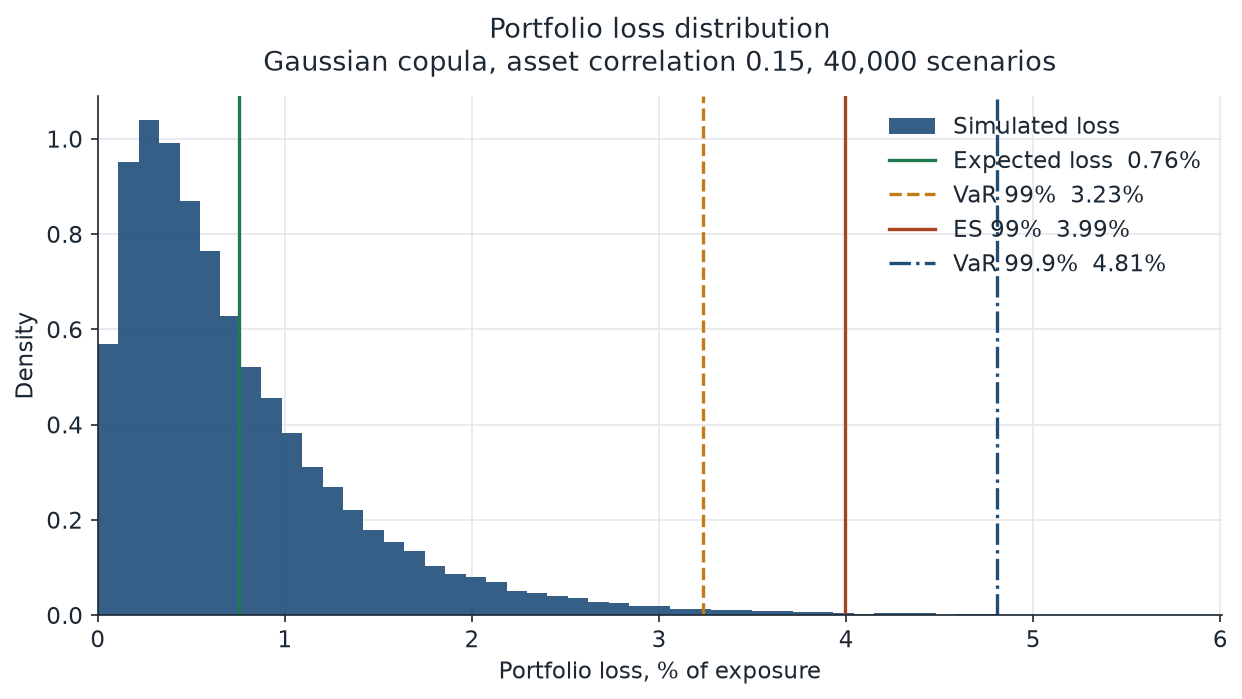

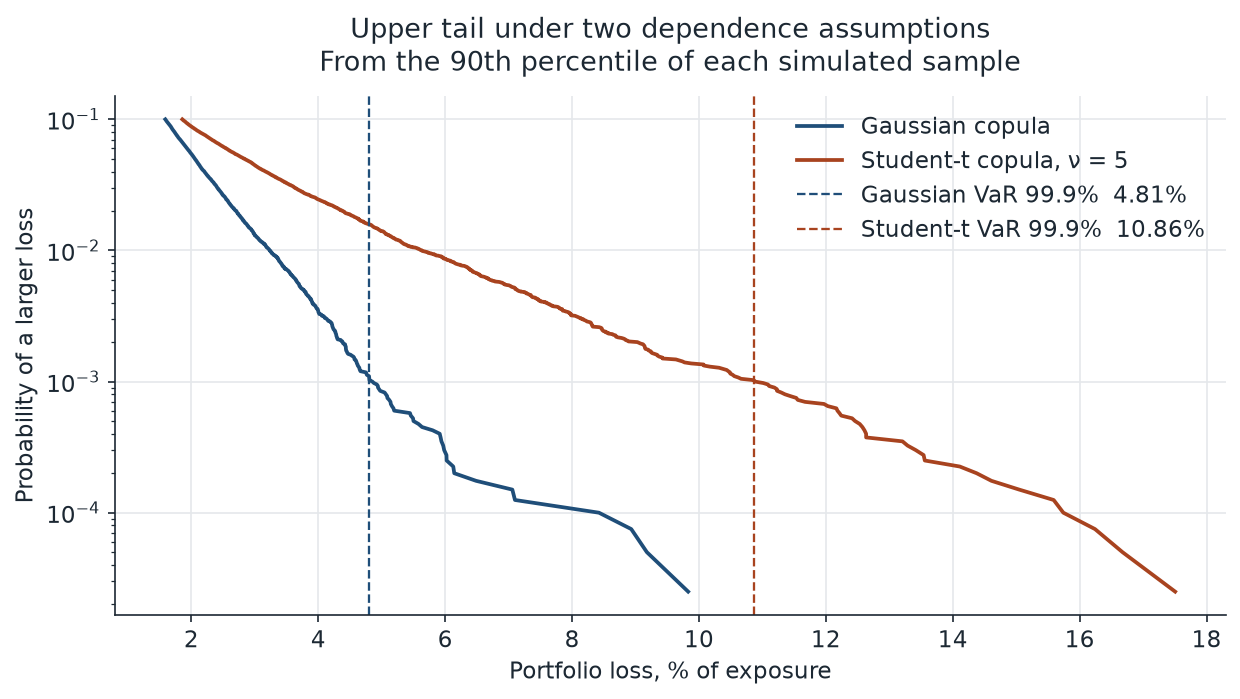

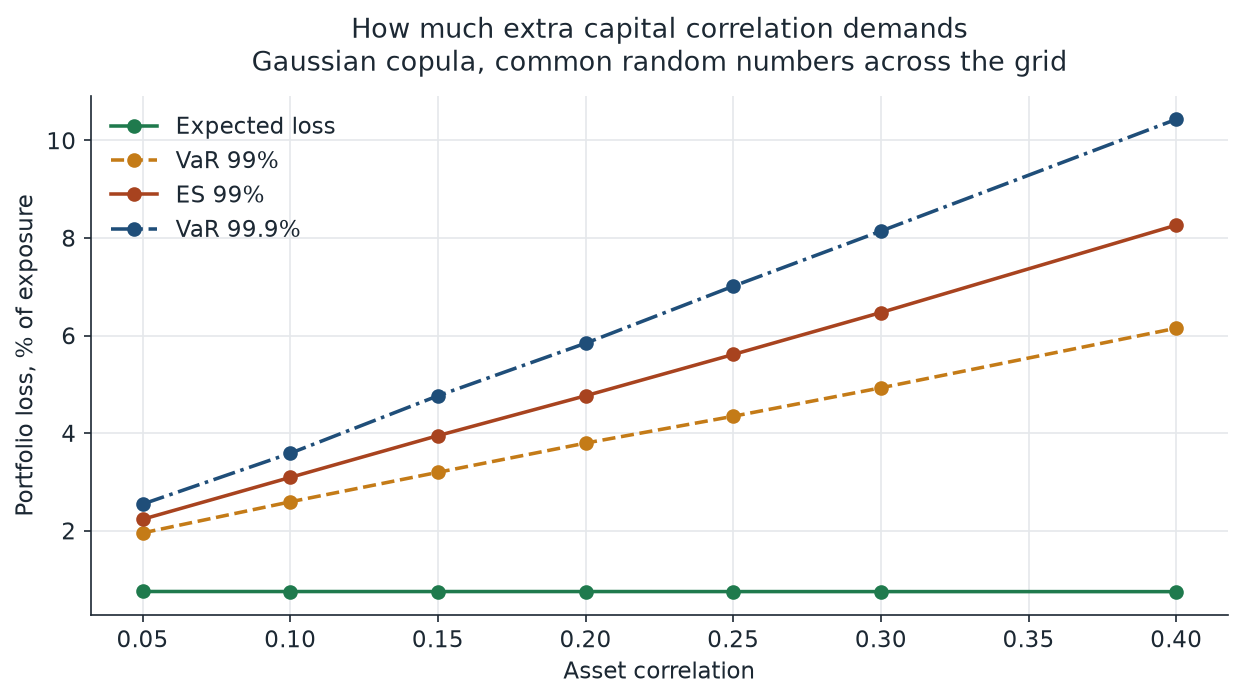

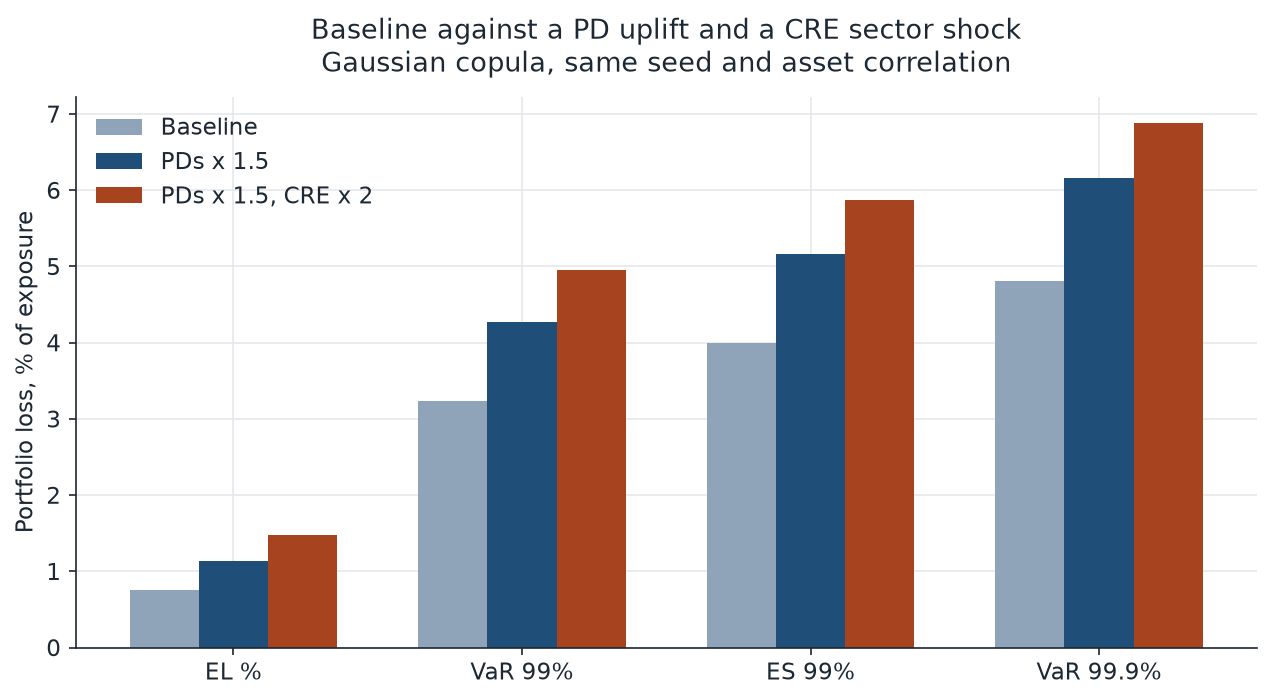

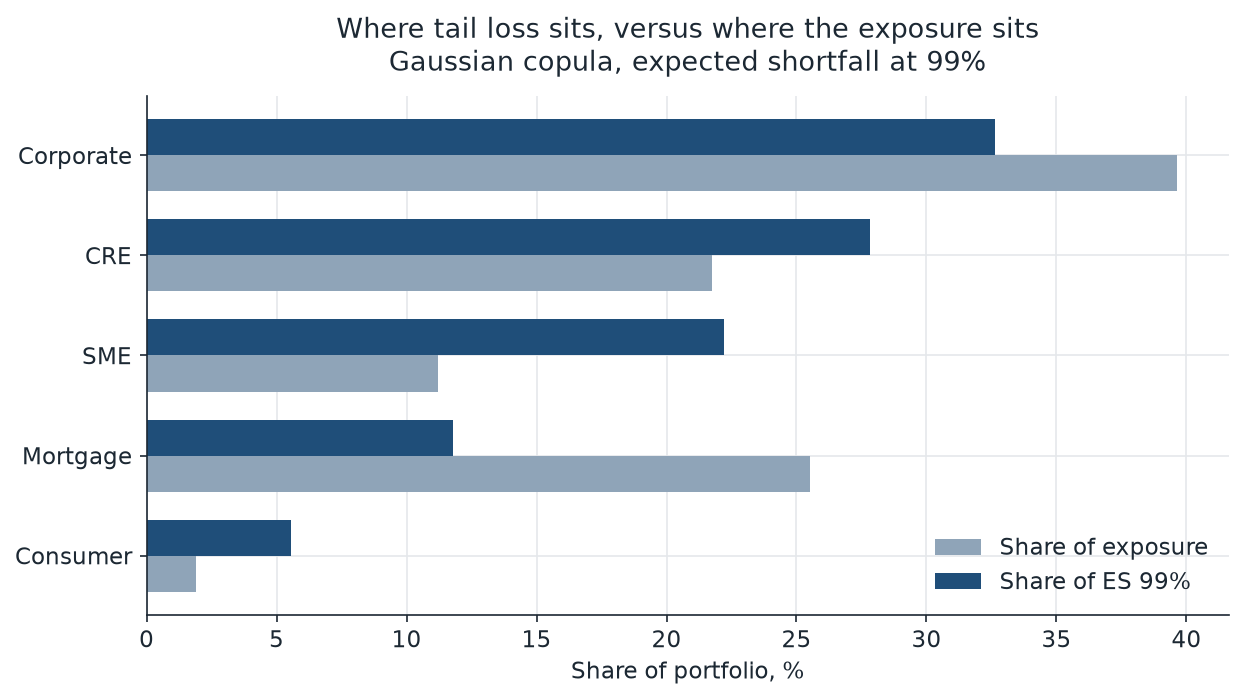

In [5]:
for name in (
    "loss_distribution.png",
    "gaussian_vs_t_tails.png",
    "correlation_sensitivity.png",
    "stress_comparison.png",
    "sector_contributions.png",
):
    display(Image(filename=str(ROOT / "docs" / name)))

## Correlation, stress, and who drives the tail

Expected loss is flat in asset correlation. VaR and expected shortfall are not. The stress multiplies every PD by 1.5, then multiplies CRE PDs by a further 2, and reruns the Gaussian copula at the same seed.


In [6]:
result.sensitivity.round(3)

,Asset correlation,EL %,VaR 95%,ES 95%,VaR 99%,ES 99%,VaR 99.9%,ES 99.9%
0,0.0500,0.7530,1.4700,1.7680,1.9530,2.2330,2.5440,2.8860
1,0.1000,0.7520,1.7780,2.2820,2.5910,3.0920,3.5860,4.2900
2,0.1500,0.7520,2.0450,2.7550,3.1960,3.9480,4.7650,5.7310
3,0.2000,0.7520,2.2800,3.2030,3.7950,4.7650,5.8430,7.2120
4,0.2500,0.7510,2.4960,3.6420,4.3450,5.6120,7.0120,8.8160
5,0.3000,0.7510,2.7010,4.0750,4.9280,6.4720,8.1420,10.4160
6,0.4000,0.7500,3.0580,4.9420,6.1510,8.2640,10.4340,13.4990


In [7]:
result.stress.round(3)

,Scenario,EL %,VaR 99%,ES 99%,VaR 99.9%,ES 99.9%
0,Baseline,0.7560,3.2340,3.9910,4.8060,5.8910
1,PDs x 1.5,1.1340,4.2750,5.1580,6.1560,7.3570
2,"PDs x 1.5, CRE x 2",1.4770,4.9540,5.8660,6.8830,8.1750


In [8]:
shares = result.contributions.copy()
for column in ("EAD share", "EL share", "ES share"):
    shares[column] = 100 * shares[column]
shares.round(1)

,Sector,EAD share,EL share,ES share
3,Corporate,39.6000,27.8000,32.6000
4,CRE,21.7000,30.3000,27.8000
2,SME,11.2000,24.7000,22.2000
0,Mortgage,25.5000,10.5000,11.8000
1,Consumer,1.9000,6.6000,5.6000


SME takes about twice as much of the 99% expected shortfall as of the exposure. Mortgage takes about half. Consumer's own loss rate is the highest on the book, and the balances are small, so the sector is a modest slice of portfolio tail loss.

The same seeds reproduce these tables from `python run_simulation.py`. The checks behind them — stable draws, expected loss against the analytic sum, ES at least VaR, VaR rising in correlation, and a heavier Student-t tail at 99.9% — are in `tests/`.
